# SteerViT: Steerable Visual Representations

This notebook provides two interactive demos to showcase the capabilities of SteerViT. For more information and further use-cases, visit the [Project Website](https://jonaruthardt.github.io/project/SteerViT/).

In [4]:
import torch
from PIL import Image

from steervit import SteerViT

device = (
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

model = SteerViT.from_pretrained("steervit_dinov2_base.pth", device=device)
transform = model.get_transforms()

image = Image.open("/Users/markpp/Datasets/spray/data/public/mvtec_loco_anomaly_detection/screw_bag/test/structural_anomalies/003.png").convert("RGB")
image_tensor = transform(image).unsqueeze(0)

prompt = ["broken plastic bag"]

global_features = model.get_global_features(image_tensor, texts=prompt)
dense_features = model.get_dense_features(image_tensor, texts=prompt)
heatmaps = model.get_heatmaps(image_tensor, texts=prompt)
attention_heatmaps = model.get_attention_heatmaps(image_tensor, texts=prompt)

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


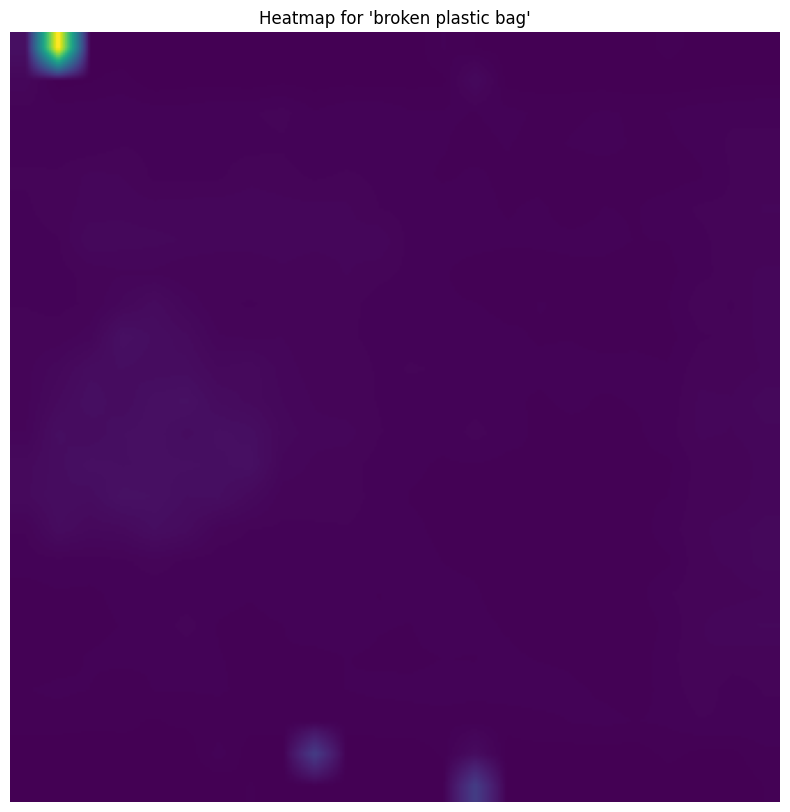

In [5]:
# Visualize the heatmaps
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 10))
for i, heatmap in enumerate(heatmaps):
    plt.subplot(1, len(heatmaps), i + 1)
    plt.imshow(heatmap.cpu().squeeze().numpy(), cmap='viridis')
    plt.title(f"Heatmap for '{prompt[i]}'")
    plt.axis('off')
plt.show()